<a href="https://colab.research.google.com/github/isurusasangaetam/financial-doc-analysis-agent/blob/main/s21367_PA2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = "/content/drive/MyDrive/s21367_PA2"
os.makedirs(PROJECT_DIR, exist_ok=True)
%cd $PROJECT_DIR

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/s21367_PA2


Install Packages

In [ ]:
!pip install -q pymupdf sentence-transformers faiss-cpu transformers accelerate langgraph fpdf2

Imports & Load Apple 10-K PDFs

In [ ]:
import fitz
import os, re, glob, json
import numpy as np
import torch
import faiss
import matplotlib.pyplot as plt
from typing import TypedDict, List, Dict, Any
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM
from langgraph.graph import StateGraph, END
from fpdf import FPDF
from fpdf.enums import XPos, YPos

pdf_paths = sorted(glob.glob(os.path.join(PROJECT_DIR, "10-K-*-As-Filed.pdf")))
assert len(pdf_paths) > 0, f"No 10-K-*-As-Filed.pdf files found in {PROJECT_DIR}"
print("Found 10-K filings:", [os.path.basename(p) for p in pdf_paths])

Found 10-K filings: ['10-K-2023-As-Filed.pdf', '10-K-2024-As-Filed.pdf', '10-K-2025-As-Filed.pdf']


Document Processing & Chunking

In [ ]:
def extract_year_from_filename(filename: str) -> str:
    match = re.search(r"(20\d{2})", filename)
    return match.group(1) if match else "unknown"

def extract_pdf_pages(pdf_path: str) -> list[dict]:
    year = extract_year_from_filename(os.path.basename(pdf_path))
    doc = fitz.open(pdf_path)
    pages = []
    for i, page in enumerate(doc, start=1):
        text = page.get_text("text").strip()
        if text:
            pages.append({
                "text": text,
                "page": i,
                "year": year,
                "source": os.path.basename(pdf_path),
            })
    return pages

def chunk_text(text: str, chunk_size: int = 250, overlap: int = 50) -> list[str]:
    words = text.split()
    if len(words) <= chunk_size:
        return [text]
    chunks, start = [], 0
    while start < len(words):
        end = start + chunk_size
        chunks.append(" ".join(words[start:end]))
        start += chunk_size - overlap
    return chunks

all_pages = []
for path in pdf_paths:
    pages = extract_pdf_pages(path)
    all_pages.extend(pages)
    print(f"{os.path.basename(path):28s} -> {len(pages)} pages")

chunks = []
for page in all_pages:
    for piece in chunk_text(page["text"]):
        chunks.append({
            "text": piece,
            "page": page["page"],
            "year": page["year"],
            "source": page["source"],
        })

print(f"Total chunks created: {len(chunks)}")

10-K-2023-As-Filed.pdf       -> 80 pages
10-K-2024-As-Filed.pdf       -> 121 pages
10-K-2025-As-Filed.pdf       -> 80 pages
Total chunks created: 867


Embeddings + FAISS

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
embed_model = SentenceTransformer("all-MiniLM-L6-v2", device=device)

chunk_texts = [c["text"] for c in chunks]
embeddings = embed_model.encode(
    chunk_texts,
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
)

faiss_index = faiss.IndexFlatIP(embeddings.shape[1])
faiss_index.add(embeddings.astype(np.float32))
print(f"FAISS index built with {faiss_index.ntotal} vectors on {device}.")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/14 [00:00<?, ?it/s]

FAISS index built with 867 vectors on cpu.


Financial Retrieval Tools

In [ ]:
def retrieve_financial_info(query: str, k: int = 5) -> list[dict]:
    query_vec = embed_model.encode([query], normalize_embeddings=True, convert_to_numpy=True)
    scores, idxs = faiss_index.search(query_vec.astype(np.float32), k)
    return [
        {
            "score": float(s),
            "text": chunks[i]["text"],
            "year": chunks[i]["year"],
            "source": chunks[i]["source"],
            "page": chunks[i]["page"],
        }
        for s, i in zip(scores[0], idxs[0])
    ]

def retrieve_within_year(query: str, year: str, k: int = 5) -> list[dict]:
    year_indices = [i for i, c in enumerate(chunks) if c["year"] == year]
    if not year_indices:
        return []
    query_vec = embed_model.encode([query], normalize_embeddings=True, convert_to_numpy=True)[0]
    year_embeddings = embeddings[year_indices]
    scores = year_embeddings @ query_vec
    top_local = np.argsort(-scores)[:k]
    return [
        {
            "score": float(scores[j]),
            "text": chunks[year_indices[j]]["text"],
            "year": year,
            "source": chunks[year_indices[j]]["source"],
            "page": chunks[year_indices[j]]["page"],
        }
        for j in top_local
    ]

def financial_retrieval_tool(query: str, k: int = 5) -> str:
    results = retrieve_financial_info(query, k=k)
    return "\n\n".join(
        f"[{r['source']} ({r['year']}) p.{r['page']}]\n{r['text']}" for r in results
    )


print(financial_retrieval_tool("Total net sales Products Services 2025 2024 2023", k=2)[:500])

[10-K-2024-As-Filed.pdf (2024) p.38]
accounts for all third-party application–related sales on a net basis by recognizing in Services net sales only the commission it retains. Net sales disaggregated by significant products and services for 2024, 2023 and 2022 were as follows (in millions): 2024 2023 2022 iPhone $ 201,183 $ 200,583 $ 205,489 Mac 29,984 29,357 40,177 iPad 26,694 28,300 29,292 Wearables, Home and Accessories 37,005 39,845 41,241 Services (1) 96,169 85,200 78,129 Total net sales $ 


Load Local LLM

In [ ]:
QWEN_MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
qwen_tokenizer = AutoTokenizer.from_pretrained(QWEN_MODEL_ID)
qwen_model = AutoModelForCausalLM.from_pretrained(
    QWEN_MODEL_ID,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto",
)
qwen_model.eval()
print("Qwen2.5-1.5B-Instruct loaded.")

def generate_with_qwen(
    prompt: str,
    system_prompt: str = "You are a precise financial analyst. Base answers strictly on the provided 10-K data.",
    max_new_tokens: int = 350,
) -> str:
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": prompt},
    ]
    text = qwen_tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = qwen_tokenizer(text, return_tensors="pt").to(qwen_model.device)
    with torch.no_grad():
        output = qwen_model.generate(
            **inputs, max_new_tokens=max_new_tokens, do_sample=False
        )
    return qwen_tokenizer.decode(
        output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True
    ).strip()

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Qwen2.5-1.5B-Instruct loaded.


Calculation Tools

In [ ]:
def parse_dollar_number(text: str) -> float | None:
    """Safely parse a dollar/numeric string (handling commas) and ignore 'not found'."""
    if not text or "not found" in text.lower():
        return None

    target = text.split("Value:")[-1].split("Year:")[0] if "Value:" in text else text
    match = re.search(r"[-+]?\d[\d,]*(?:\.\d+)?", target)
    if not match:
        return None
    return float(match.group(0).replace(",", ""))

def extract_financial_metric(metric_name: str, context_text: str, year: str) -> str:
    """Extract a single financial metric (in $ millions) for a given fiscal year."""
    prompt = f"""From the Apple 10-K text below, extract ONLY the numeric value (in millions of dollars) for "{metric_name}" for fiscal year {year}.
Reply in this exact format:
Value: <number> million, Year: {year}
If not found, reply: Value: not found

Text:
{context_text}
"""
    return generate_with_qwen(prompt, max_new_tokens=40)

def extract_category_revenues(context_text: str, year: str) -> dict[str, float]:
    """Extract Apple's 5 product/service category net sales (in $ millions) for a specific year."""
    prompt = f"""From the Apple 10-K table below, extract the net sales (in millions) for fiscal year {year} for these five categories:
iPhone, Mac, iPad, Wearables, Home and Accessories, Services.
Reply with ONLY five lines in this exact format (numbers only, no $ sign):
iPhone: <number>
Mac: <number>
iPad: <number>
Wearables, Home and Accessories: <number>
Services: <number>

Text:
{context_text}
"""
    raw = generate_with_qwen(prompt, max_new_tokens=100)
    categories = {}
    for line in raw.split("\n"):
        if ":" in line:
            label, val_part = line.split(":", 1)
            num = parse_dollar_number(val_part)
            if num is not None and num > 0:
                categories[label.strip()] = num
    return categories


def calculate_percent_change(value_old: float, value_new: float) -> dict:
    """Compute exact absolute and percentage change between two years."""
    abs_change = value_new - value_old
    pct_change = (abs_change / value_old) * 100.0 if value_old != 0 else None
    return {
        "old_value_millions": round(value_old, 2),
        "new_value_millions": round(value_new, 2),
        "absolute_change_millions": round(abs_change, 2),
        "percent_change": round(pct_change, 2) if pct_change is not None else None,
    }

def analyze_category_contributions(category_values: dict[str, float]) -> dict:
    """Compute total revenue, each category's % share, and the highest/lowest contributors."""
    if not category_values:
        return {"note": "No category values extracted."}
    total = sum(category_values.values())
    shares = {
        cat: round((val / total) * 100.0, 2)
        for cat, val in category_values.items()
    }
    top_cat = max(category_values, key=category_values.get)
    low_cat = min(category_values, key=category_values.get)
    return {
        "total_millions": round(total, 2),
        "shares_percent": shares,
        "top_category": top_cat,
        "top_category_value_millions": category_values[top_cat],
        "top_category_share_percent": shares[top_cat],
        "lowest_category": low_cat,
        "lowest_category_value_millions": category_values[low_cat],
    }

Report Generation Tool

In [ ]:
def generate_financial_report(
    question: str,
    metric_name: str,
    values_by_year: dict,
    category_values: dict,
    calc_result: dict,
) -> str:
    data_note = (
        "IMPORTANT: Insufficient numeric data was extracted. State this clearly without inventing numbers."
        if "note" in calc_result
        else "Use ONLY the exact numbers provided below. Do not recalculate or invent figures."
    )
    prompt = f"""Write a concise, plain-text 2-paragraph financial analysis (no markdown symbols, no bullet points, no headers) answering:
{question}

Metric / Focus: {metric_name}
Values by year ($ millions): {values_by_year}
Category breakdown ($ millions): {category_values}
Python-verified calculation results: {calc_result}

{data_note}
"""
    return generate_with_qwen(prompt, max_new_tokens=280)

LangGraph State

In [ ]:
class FinancialAgentState(TypedDict):
    question: str
    metric_name: str
    analysis_type: str
    target_years: List[str]
    retrieved_context: str
    values_by_year: Dict[str, str]
    numbers_found: Dict[str, float]
    category_values: Dict[str, float]
    calc_result: Dict[str, Any]
    report: str
    next_action: str
    steps_done: List[str]

Planner

In [ ]:
def planner_node(state: FinancialAgentState) -> FinancialAgentState:
    steps_done = state.get("steps_done", [])
    has_context = bool(state.get("retrieved_context"))
    has_calc = bool(state.get("calc_result"))
    has_report = bool(state.get("report"))

    prompt = f"""You are a financial analysis agent planner. Choose the single next action.

Steps already completed: {steps_done if steps_done else 'none'}
Has retrieved context: {'yes' if has_context else 'no'}
Has calculated results: {'yes' if has_calc else 'no'}
Has final report: {'yes' if has_report else 'no'}

Rules:
- If no context retrieved yet -> RETRIEVE
- If context exists but no calculation yet -> CALCULATE
- If calculation exists but no report yet -> REPORT
- If report exists -> FINISH

Reply with exactly one word: RETRIEVE, CALCULATE, REPORT, or FINISH.
"""
    decision = generate_with_qwen(prompt, max_new_tokens=10).strip().upper()
    chosen = "FINISH"
    for action in ["RETRIEVE", "CALCULATE", "REPORT", "FINISH"]:
        if action in decision:
            chosen = action
            break

    if chosen == "RETRIEVE" and has_context:
        chosen = "CALCULATE" if not has_calc else ("REPORT" if not has_report else "FINISH")
    elif chosen == "CALCULATE" and has_calc:
        chosen = "REPORT" if not has_report else "FINISH"
    elif chosen == "REPORT" and has_report:
        chosen = "FINISH"

    state["next_action"] = chosen
    return state

Action Nodes

In [ ]:
def retrieve_node(state: FinancialAgentState) -> FinancialAgentState:
    query = f"{state['metric_name']} {state['question']} net sales millions"
    state["retrieved_context"] = financial_retrieval_tool(query, k=6)
    state["steps_done"].append("RETRIEVE")
    return state

def calculate_node(state: FinancialAgentState) -> FinancialAgentState:
    if state["analysis_type"] == "category_breakdown":
        latest_year = state["target_years"][-1]
        results = retrieve_within_year(
            "Net sales by category iPhone Mac iPad Wearables Home and Accessories Services",
            latest_year,
            k=5,
        )
        year_context = "\n".join(r["text"] for r in results)
        cat_vals = extract_category_revenues(year_context, latest_year)
        state["category_values"] = cat_vals
        state["calc_result"] = analyze_category_contributions(cat_vals)
    else:
        values_by_year = {}
        numbers = {}
        for year in state["target_years"]:
            results = retrieve_within_year(
                f"{state['metric_name']} {year} net sales dollars in millions",
                year,
                k=5,
            )
            year_context = "\n".join(r["text"] for r in results)
            if year_context:
                raw_val = extract_financial_metric(state["metric_name"], year_context, year)
                values_by_year[year] = raw_val
                parsed = parse_dollar_number(raw_val)
                if parsed is not None:
                    numbers[year] = parsed

        state["values_by_year"] = values_by_year
        state["numbers_found"] = numbers

        if len(numbers) >= 2:
            y_sorted = sorted(numbers.keys())
            state["calc_result"] = calculate_percent_change(
                numbers[y_sorted[0]], numbers[y_sorted[-1]]
            )
        else:
            state["calc_result"] = {"note": "Not enough numeric values extracted to compute change."}

    state["steps_done"].append("CALCULATE")
    return state

def report_node(state: FinancialAgentState) -> FinancialAgentState:
    state["report"] = generate_financial_report(
        state["question"],
        state["metric_name"],
        state["values_by_year"],
        state["category_values"],
        state["calc_result"],
    )
    state["steps_done"].append("REPORT")
    return state

Routing

In [ ]:
def route_from_planner(state: FinancialAgentState) -> str:
    mapping = {"RETRIEVE": "retrieve", "CALCULATE": "calculate", "REPORT": "report"}
    return mapping.get(state.get("next_action", "FINISH"), END)

graph = StateGraph(FinancialAgentState)
graph.add_node("planner", planner_node)
graph.add_node("retrieve", retrieve_node)
graph.add_node("calculate", calculate_node)
graph.add_node("report", report_node)

graph.set_entry_point("planner")
graph.add_conditional_edges("planner", route_from_planner)
graph.add_edge("retrieve", "planner")
graph.add_edge("calculate", "planner")
graph.add_edge("report", "planner")

agent = graph.compile()
print("Financial Document Analysis Agent compiled successfully.")

Financial Document Analysis Agent compiled successfully.


Run Test Questions

In [ ]:
def run_agent(question: str, metric_name: str, analysis_type: str, target_years: list[str]) -> FinancialAgentState:
    init_state: FinancialAgentState = {
        "question": question,
        "metric_name": metric_name,
        "analysis_type": analysis_type,
        "target_years": target_years,
        "retrieved_context": "",
        "values_by_year": {},
        "numbers_found": {},
        "category_values": {},
        "calc_result": {},
        "report": "",
        "next_action": "",
        "steps_done": [],
    }
    result = agent.invoke(init_state, config={"recursion_limit": 20})
    print(f"Question: {question}")
    print(f"Steps taken: {result['steps_done']}")
    print(f"Calculation result: {result['calc_result']}")
    print(f"\n=== GENERATED REPORT ===\n{result['report']}\n" + "=" * 60 + "\n")
    return result

# Q1: Total revenue change (2023 - 2025)
state_q1 = run_agent(
    question="How did the company's total revenue change between 2023 and 2025?",
    metric_name="Total net sales",
    analysis_type="trend",
    target_years=["2023", "2024", "2025"],
)

# Q2: Top product category in latest year (2025)
state_q2 = run_agent(
    question="Which product category contributed the most revenue in the latest year?",
    metric_name="Net sales by category",
    analysis_type="category_breakdown",
    target_years=["2025"],
)

# Q3: Custom financial analysis question (Services revenue growth 2023 - 2025)
state_q3 = run_agent(
    question="How did Apple's Services net sales change between 2023 and 2025?",
    metric_name="Services net sales",
    analysis_type="trend",
    target_years=["2023", "2024", "2025"],
)

Question: How did the company's total revenue change between 2023 and 2025?
Steps taken: ['RETRIEVE', 'CALCULATE', 'REPORT']
Calculation result: {'old_value_millions': 383285.0, 'new_value_millions': 416161.0, 'absolute_change_millions': 32876.0, 'percent_change': 8.58}

=== GENERATED REPORT ===
The company's total net sales increased from $383,285 million in 2023 to $416,161 million in 2025, marking an absolute increase of $32,876 million over two years. This represents an approximate 8.58% growth in total net sales from 2023 to 2025. The consistent rise in sales suggests that the company has been successfully expanding its market presence and increasing customer demand during this period.

Question: Which product category contributed the most revenue in the latest year?
Steps taken: ['RETRIEVE', 'CALCULATE', 'REPORT']
Calculation result: {'total_millions': 416161.0, 'shares_percent': {'iPhone': 50.36, 'Mac': 8.1, 'iPad': 6.73, 'Wearables, Home and Accessories': 8.58, 'Services': 26.2

Charts

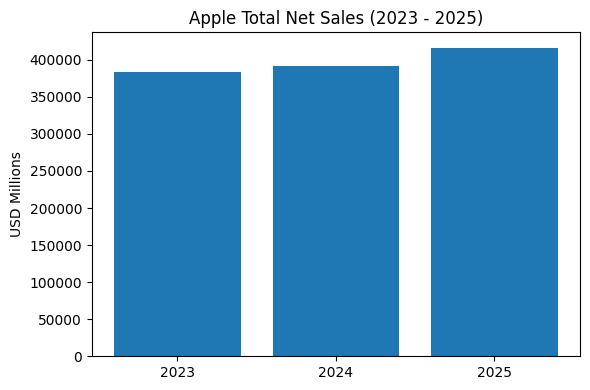

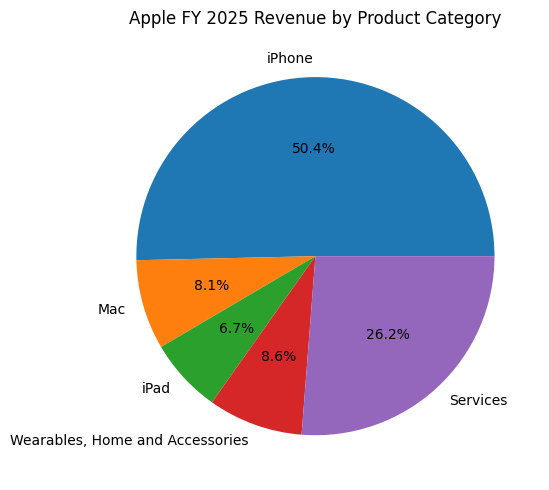

In [ ]:
def clean_text(text: str) -> str:
    """Replace non-latin1 characters so FPDF Helvetica renders cleanly."""
    return text.encode("latin-1", "replace").decode("latin-1")

# Chart 1: Total Revenue Trend (Q1)
if state_q1["numbers_found"]:
    yrs = sorted(state_q1["numbers_found"].keys())
    vals = [state_q1["numbers_found"][y] for y in yrs]
    plt.figure(figsize=(6, 4))
    plt.bar(yrs, vals, color="#1f77b4")
    plt.title("Apple Total Net Sales (2023 - 2025)")
    plt.ylabel("USD Millions")
    plt.tight_layout()
    plt.savefig(os.path.join(PROJECT_DIR, "q1_revenue_trend.png"), dpi=150)
    plt.show()

# Chart 2: Product Category Share (Q2)
if state_q2["category_values"]:
    plt.figure(figsize=(6, 5))
    plt.pie(
        state_q2["category_values"].values(),
        labels=state_q2["category_values"].keys(),
        autopct="%1.1f%%",
    )
    plt.title("Apple FY 2025 Revenue by Product Category")
    plt.tight_layout()
    plt.savefig(os.path.join(PROJECT_DIR, "q2_category_share.png"), dpi=150)
    plt.show()

Export PDF

In [ ]:
def export_assignment_pdf(results: list[tuple[str, FinancialAgentState]], out_path: str):
    pdf = FPDF()
    pdf.set_auto_page_break(auto=True, margin=15)
    pdf.add_page()
    pdf.set_font("Helvetica", "B", 16)
    pdf.cell(pdf.epw, 10, "Financial Document Analysis Agent - Output Report", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
    pdf.set_font("Helvetica", "I", 10)
    pdf.cell(pdf.epw, 6, "Knowledge Source: Apple Inc. Form 10-K Filings (FY 2023, FY 2024, FY 2025)", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
    pdf.ln(4)

    for title, st in results:
        pdf.set_x(pdf.l_margin)
        pdf.set_font("Helvetica", "B", 12)
        pdf.multi_cell(pdf.epw, 7, clean_text(f"{title}: {st['question']}"), new_x=XPos.LMARGIN, new_y=YPos.NEXT)

        pdf.set_font("Helvetica", "", 10)
        pdf.multi_cell(pdf.epw, 5, clean_text(f"Workflow Steps: {' -> '.join(st['steps_done'])} -> FINISH"), new_x=XPos.LMARGIN, new_y=YPos.NEXT)
        pdf.multi_cell(pdf.epw, 5, clean_text(f"Calculated Data: {json.dumps(st['calc_result'])}"), new_x=XPos.LMARGIN, new_y=YPos.NEXT)
        pdf.ln(2)
        pdf.multi_cell(pdf.epw, 5, clean_text(st["report"]), new_x=XPos.LMARGIN, new_y=YPos.NEXT)
        pdf.ln(5)

    if os.path.exists(os.path.join(PROJECT_DIR, "q1_revenue_trend.png")):
        pdf.add_page()
        pdf.set_font("Helvetica", "B", 12)
        pdf.cell(pdf.epw, 8, "Visualizations", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
        pdf.image(os.path.join(PROJECT_DIR, "q1_revenue_trend.png"), w=140)
        pdf.ln(4)
    if os.path.exists(os.path.join(PROJECT_DIR, "q2_category_share.png")):
        pdf.image(os.path.join(PROJECT_DIR, "q2_category_share.png"), w=140)

    pdf.output(out_path)
    print(f"Saved final PDF report to: {out_path}")

export_assignment_pdf(
    [("Q1", state_q1), ("Q2", state_q2), ("Q3", state_q3)],
    os.path.join(PROJECT_DIR, "financial_analysis_report_s21367.pdf"),
)

Saved final PDF report to: /content/drive/MyDrive/s21367_PA2/financial_analysis_report_s21367.pdf
